# Adiac Visualisation and Analysis

This notebook explores the Adiac training data for our FCN project. We look at the sequence shapes, local changes, class variation and distances between samples.

## Step 1. Load the training data

Load the Adiac training set and separate the class labels from the sequence values. Check the number of samples, sequence length and number of classes.

The first column contains the class label. The remaining columns contain the sequence values. Run this notebook from the repository root, where the Adiac folder is located.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

train_data = np.loadtxt("Adiac/Adiac_TRAIN", delimiter=",")

y_train = train_data[:, 0].astype(int)
X_train = train_data[:, 1:]

print("Training samples:", X_train.shape[0])
print("Series length:", X_train.shape[1])
print("Number of classes:", len(np.unique(y_train)))

Training samples: 390
Series length: 176
Number of classes: 37


## Step 2. Plot selected training samples

Plot the first three training samples from Classes 1, 2 and 3. Compare their overall shapes and the variation between samples from the same class.

The sample indices and sequence positions start at zero. These examples provide an initial view of the data rather than representing all 37 classes.

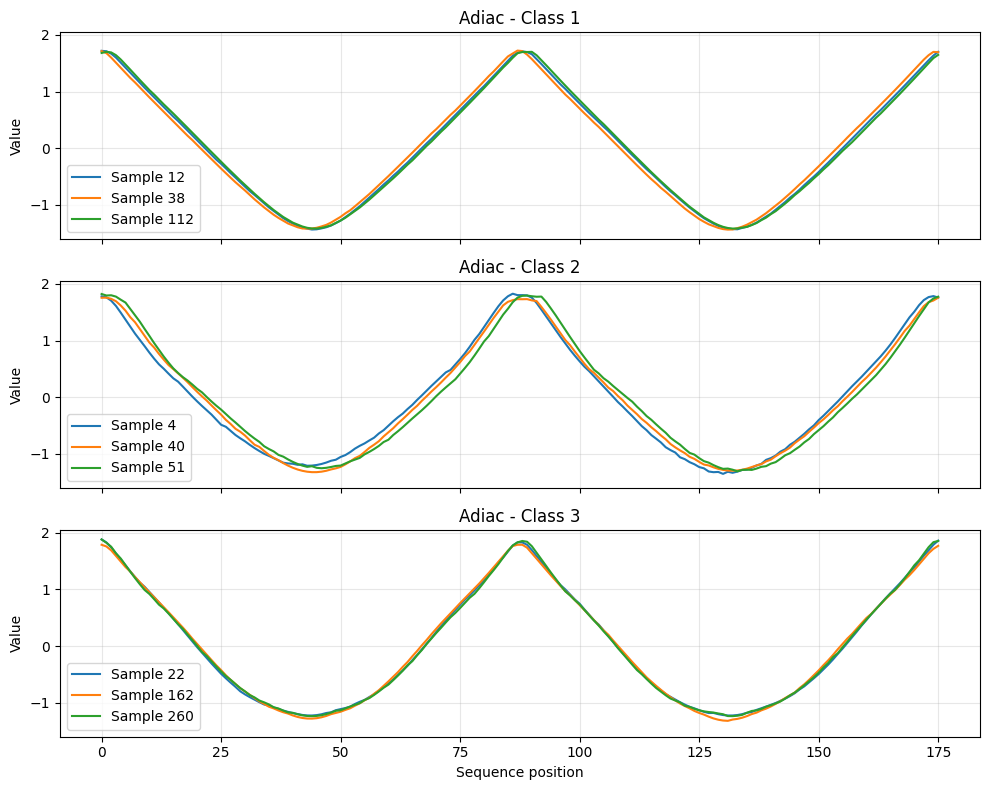

In [2]:
# Show three samples from each selected class
selected_classes = [1, 2, 3]

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, sharey=True)

for ax, class_label in zip(axes, selected_classes):
    indices = np.where(y_train == class_label)[0][:3]

    for index in indices:
        ax.plot(X_train[index], label=f"Sample {index}")

    ax.set_title(f"Adiac - Class {class_label}")
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Sequence position")
plt.tight_layout()
plt.show()

## Step 3. Examine first-order differences

Calculate the difference between neighbouring values in each sequence. Plot the same samples as before to make local rises, falls and changes in slope easier to see.

Each differenced sequence has 175 values, compared with 176 in the original sequence.

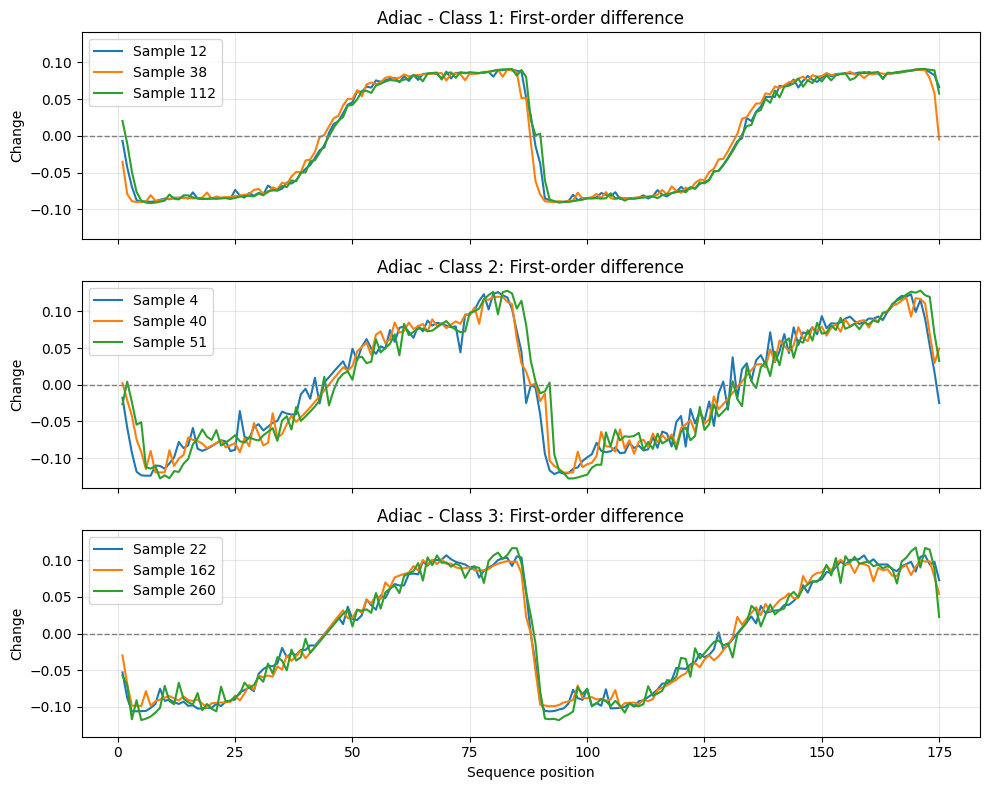

In [3]:
# Calculate changes between neighbouring points
X_diff = np.diff(X_train, axis=1)

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, sharey=True)

for ax, class_label in zip(axes, selected_classes):
    indices = np.where(y_train == class_label)[0][:3]

    for index in indices:
        ax.plot(
            np.arange(1, X_train.shape[1]),
            X_diff[index],
            label=f"Sample {index}"
        )

    ax.set_title(f"Adiac - Class {class_label}: First-order difference")
    ax.set_ylabel("Change")
    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Sequence position")
plt.tight_layout()
plt.show()

### Observations from first-order differences

The first-order difference plots make the local changes easier to see.
For the selected samples, Class 1 has smoother curves, and the three
samples are very similar. Class 2 has more local fluctuations and more
visible differences between samples. Class 3 has a similar overall
pattern, with some local variations around the positive peaks.

This suggests that looking only at the overall shape may miss some
differences between classes. Local slopes and transitions may also be
useful for classification. In an FCN, convolutional filters slide across
the sequence and can learn these local patterns from the original input.

These observations are based on only three samples from each of three
classes, so they may not represent the whole dataset. The plots also
do not show whether first-order differencing improves classification
accuracy. We would need a separate experiment to check this.

## Step 4. Examine autocorrelation

Calculate the biased sample ACF for the same selected samples, using the mean of each full sequence. Plot lags from 0 to 100 to explore how values relate to values at other sequence positions.

Here, lag measures separation in sequence positions rather than elapsed time.

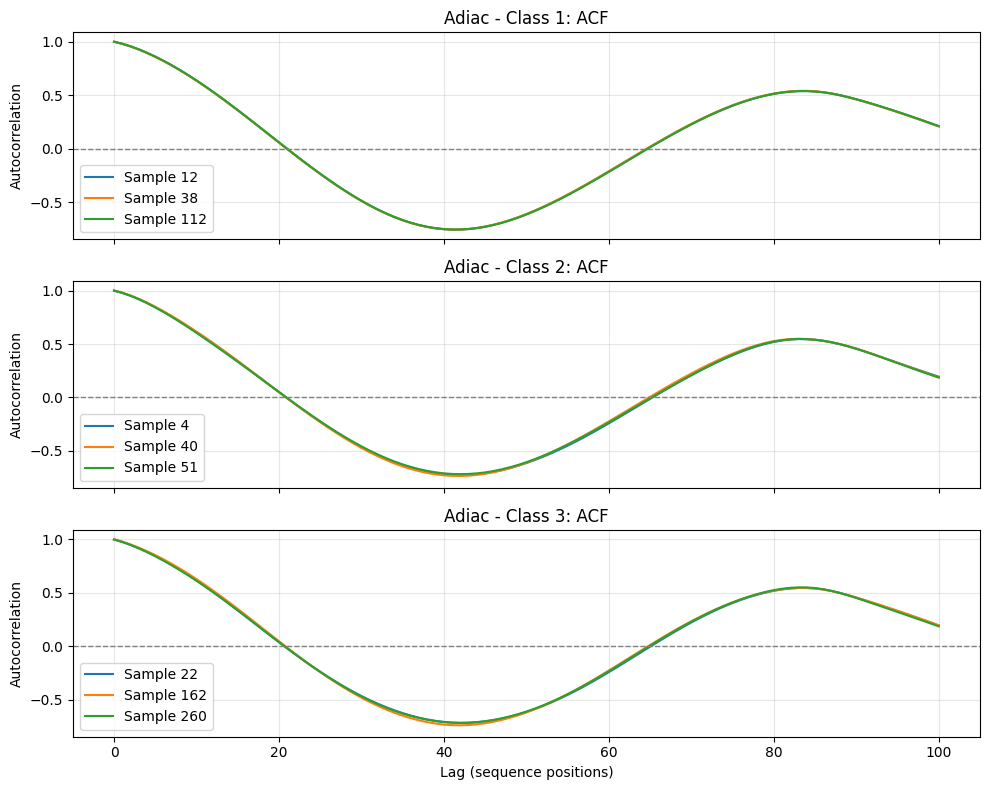

In [4]:
# Biased sample ACF using the global mean
def calculate_acf(series, max_lag):
    centred = series - np.mean(series)
    denominator = np.sum(centred ** 2)

    acf_values = [1.0]  # Lag 0 compares the sequence with itself

    for lag in range(1, max_lag + 1):
        numerator = np.sum(centred[:-lag] * centred[lag:])
        acf_values.append(numerator / denominator)

    return np.array(acf_values)


# Use the same samples as in the previous plots
max_lag = 100
lags = np.arange(max_lag + 1)

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, sharey=True)

for ax, class_label in zip(axes, selected_classes):
    indices = np.where(y_train == class_label)[0][:3]

    for index in indices:
        acf_values = calculate_acf(X_train[index], max_lag)
        ax.plot(lags, acf_values, label=f"Sample {index}")

    ax.set_title(f"Adiac - Class {class_label}: ACF")
    ax.set_ylabel("Autocorrelation")
    ax.axhline(0, color="grey", linestyle="--", linewidth=1)
    ax.legend()
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Lag (sequence positions)")
plt.tight_layout()
plt.show()

### ACF observations

The ACF curves are very similar across the selected samples from
Classes 1, 2 and 3. Autocorrelation is high at small lags, which is
consistent with the smooth changes seen in the original sequences.
The curves reach a negative minimum around lag 40–45 and another
positive peak around lag 80–85. This suggests a repeated structure
within the sequences.

For these samples, the ACF plots do not show clear differences between
classes. The first-order difference plots make some local variations
easier to see. This suggests that local details may be useful to
investigate alongside the overall sequence structure.

Here, lag refers to sequence positions. The repeated structure alone
does not establish temporal seasonality. These observations are also
limited to the nine selected training samples.

## Step 5. Check the class distribution

Count the training samples in each of the 37 classes. Plot the counts to check how evenly the classes are represented.

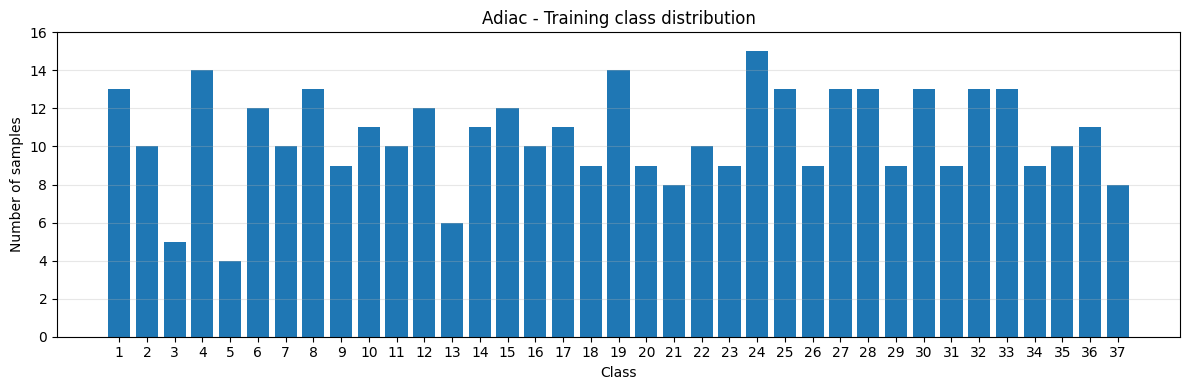

Smallest class size: 4
Largest class size: 15


In [5]:
# Count the training samples in each class
classes, counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(12, 4))
plt.bar(classes, counts)

plt.title("Adiac - Training class distribution")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.xticks(classes)
plt.yticks(np.arange(0, counts.max() + 2, 2))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Smallest class size:", counts.min())
print("Largest class size:", counts.max())

### Training class distribution

The training set contains 390 samples across 37 classes. The number
of samples per class ranges from 4 to 15. Class 5 has the fewest
samples, while Class 24 has the most. There are about 10.5 training
samples per class on average.

The classes are not equally represented, and each class has relatively
few training examples. Classes with fewer samples may be harder for
the FCN to learn, but we cannot confirm this from the counts alone.

When model predictions are available, we can check per-class recall
and the confusion matrix to see which classes are difficult to
classify. Macro-F1 would also be useful alongside overall accuracy,
since it gives each class equal weight.

## Step 6. Compare class means and variation

Calculate the mean and standard deviation at each sequence position for every class. Plot all 37 class means with shaded bands showing ±1 standard deviation.

Use these plots to compare overall shapes and identify positions with more within-class variation. The shaded bands are not confidence intervals.

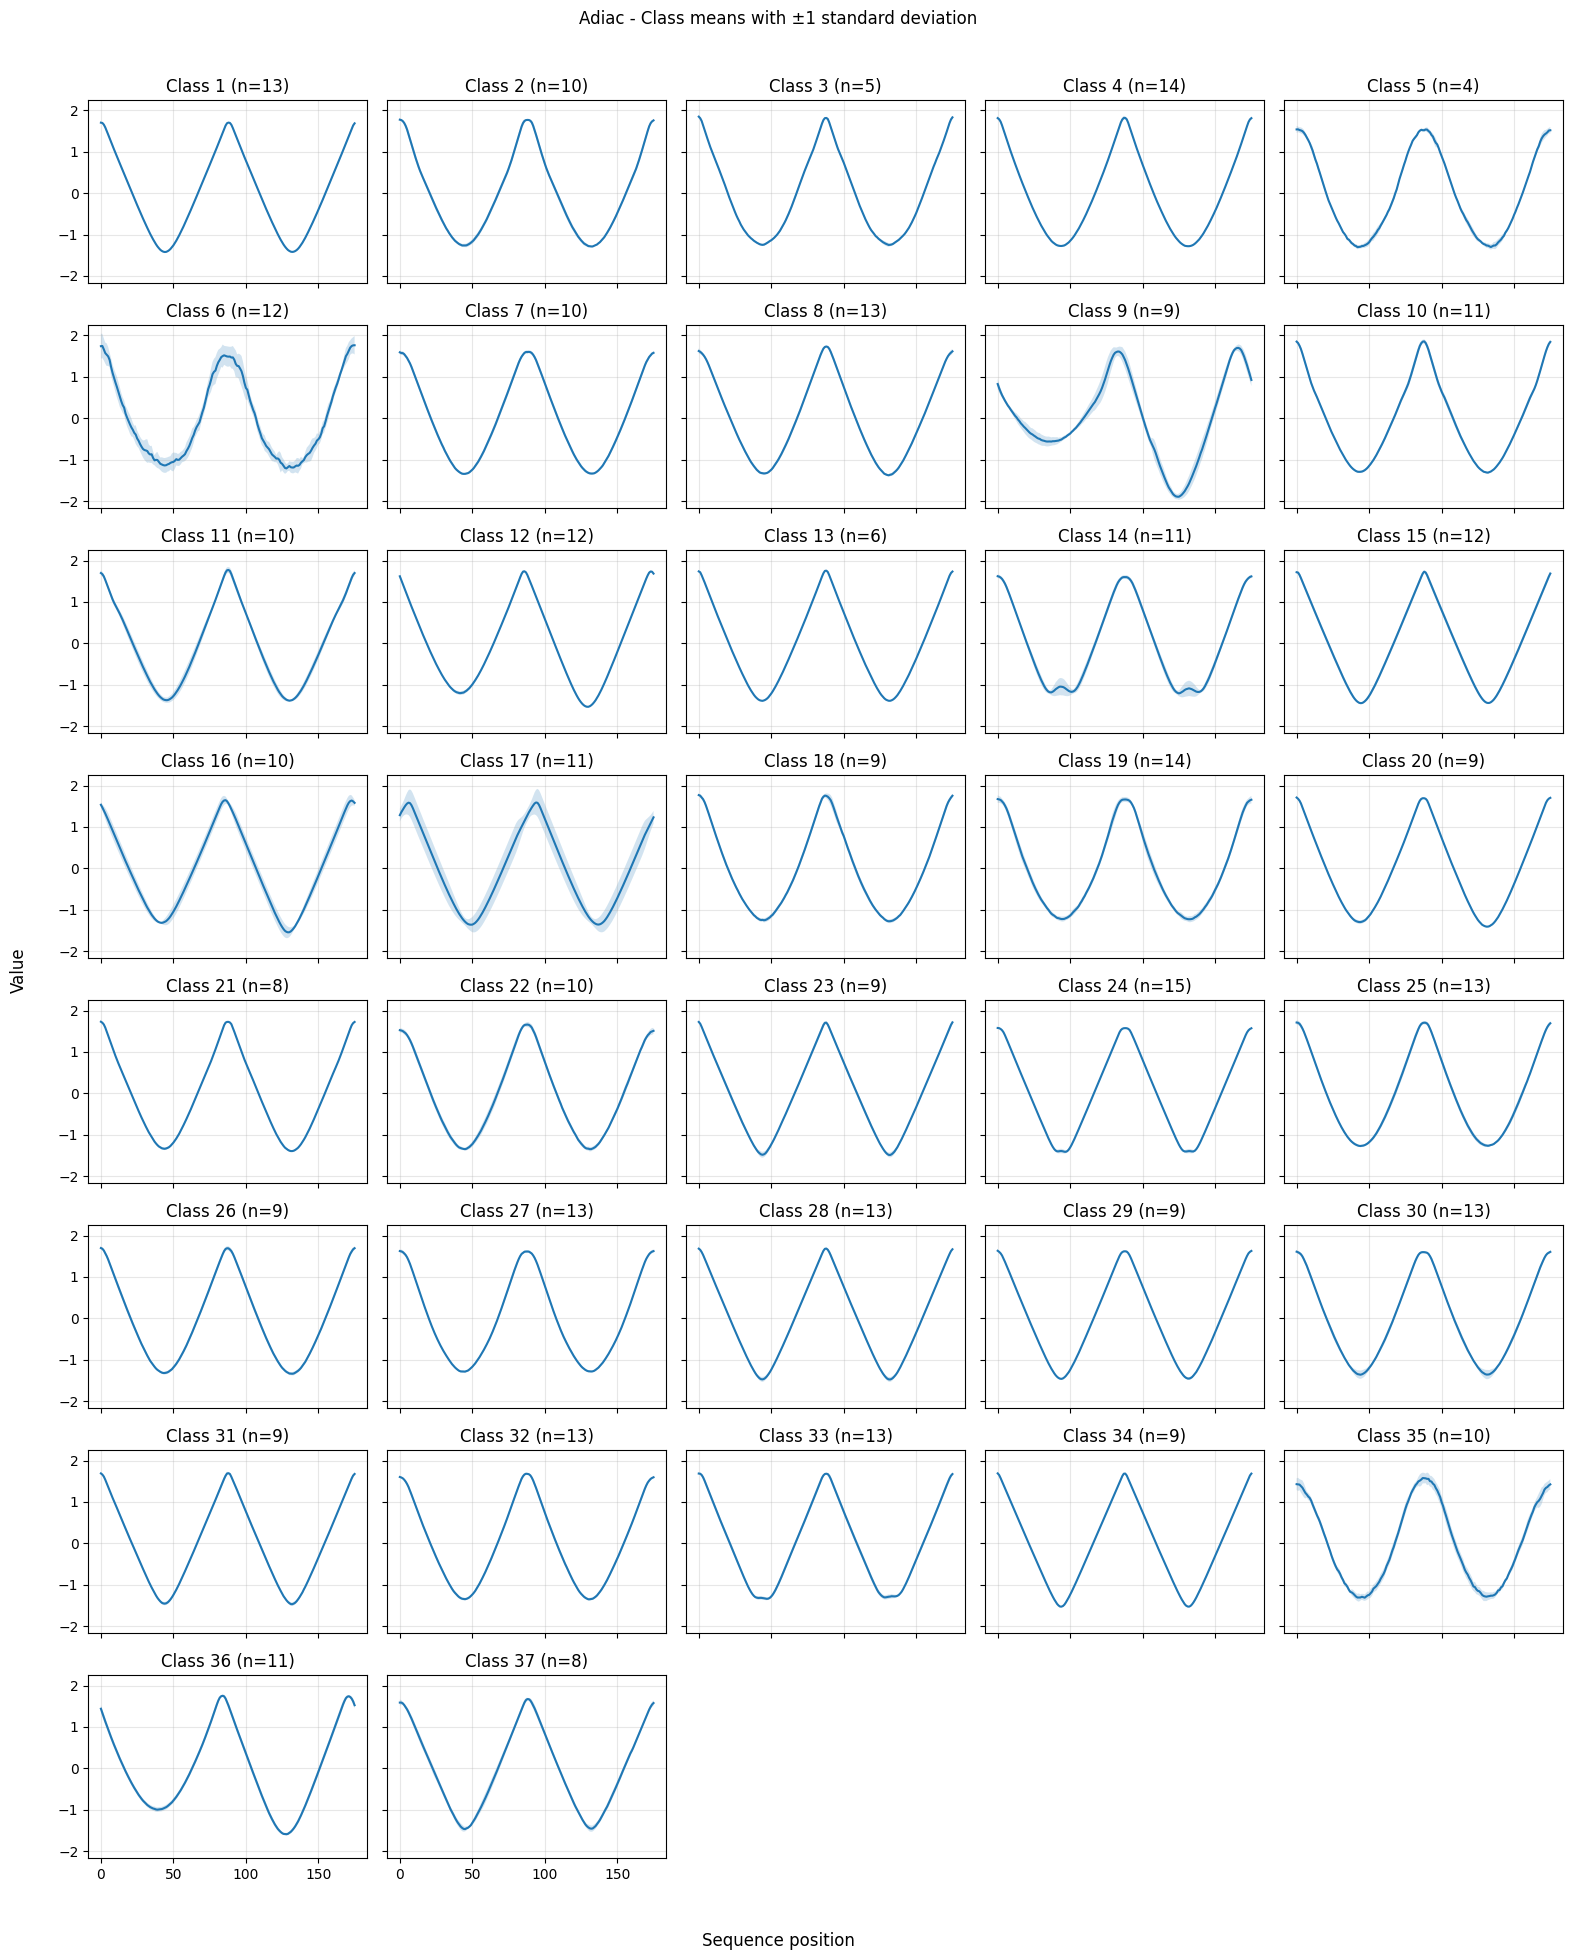

In [6]:
# Show the mean and variation for every training class
fig, axes = plt.subplots(
    8, 5, figsize=(16, 20), sharex=True, sharey=True
)

positions = np.arange(X_train.shape[1])

for ax, class_label in zip(axes.flat, classes):
    class_samples = X_train[y_train == class_label]

    class_mean = np.mean(class_samples, axis=0)
    class_std = np.std(class_samples, axis=0)

    ax.plot(positions, class_mean)
    ax.fill_between(
        positions,
        class_mean - class_std,
        class_mean + class_std,
        alpha=0.2
    )

    ax.set_title(f"Class {class_label} (n={len(class_samples)})")
    ax.grid(alpha=0.3)

# Hide the three unused panels
for ax in axes.flat[len(classes):]:
    ax.set_visible(False)

fig.supxlabel("Sequence position")
fig.supylabel("Value")
fig.suptitle("Adiac - Class means with ±1 standard deviation")

plt.tight_layout(rect=[0.02, 0.02, 1, 0.97])
plt.show()

### Class means and within-class variation

Many of the 37 classes share a similar overall shape, with two troughs
and a central peak. However, the peak heights, trough depths and local
shapes differ between classes. Classes 9 and 36 have visibly unequal
trough depths, while Classes 14 and 33 show local bumps or flatter
regions near the troughs.

The shaded bands also vary between classes. For example, Classes 6
and 17 show wider bands in parts of the sequence, indicating more
within-class variation at those positions. Many other classes have
narrow bands at this plotting scale.

These plots use all 390 training samples. They suggest that both
overall shape and local details may be useful for classification.
However, class means can hide individual patterns, and the shaded
bands show ±1 standard deviation rather than confidence intervals.
We still need model results to check which differences the FCN uses
and which classes it confuses.

## Step 7. Take a closer look at selected class means

Overlay the means of Classes 1, 9, 14, 33 and 36, selected after inspecting the previous plots. Zoom in on positions 30–60 to compare the local shapes around the first trough.

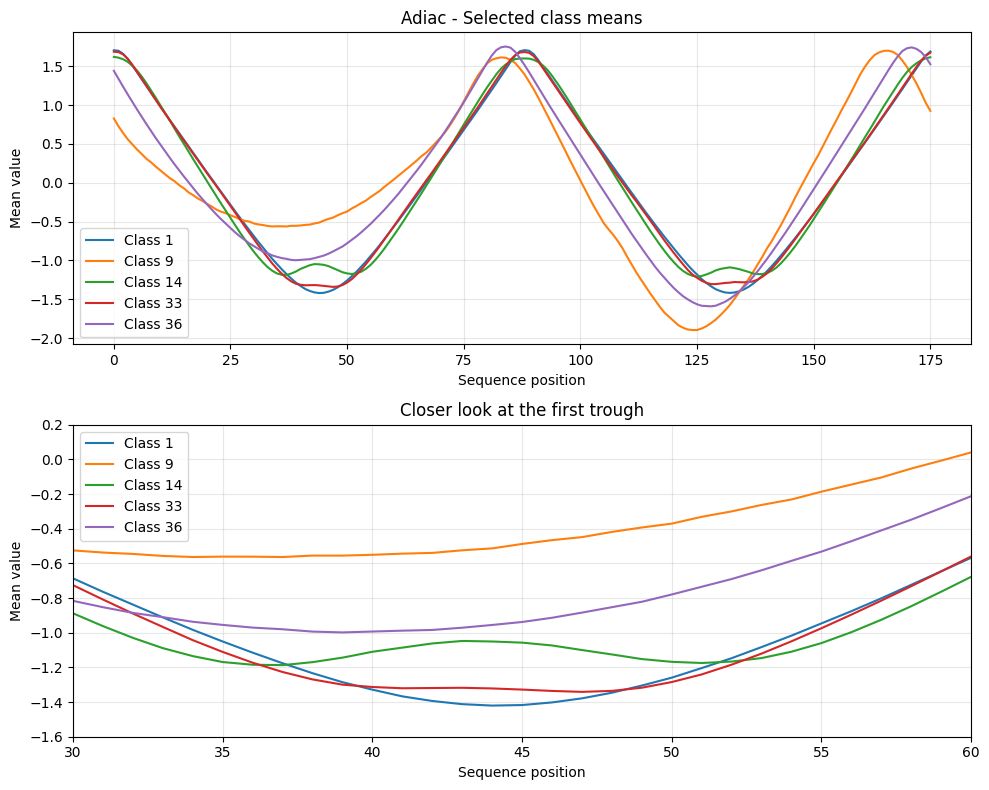

In [7]:
# Compare classes with different visible shape features
comparison_classes = [1, 9, 14, 33, 36]
positions = np.arange(X_train.shape[1])

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

for class_label in comparison_classes:
    class_samples = X_train[y_train == class_label]
    class_mean = np.mean(class_samples, axis=0)

    for ax in axes:
        ax.plot(
            positions,
            class_mean,
            label=f"Class {class_label}"
        )

axes[0].set_title("Adiac - Selected class means")
axes[1].set_title("Closer look at the first trough")
axes[1].set_xlim(30, 60)
axes[1].set_ylim(-1.6, 0.2)

for ax in axes:
    ax.set_xlabel("Sequence position")
    ax.set_ylabel("Mean value")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Comparing selected class means

Overlaying the class means makes their differences easier to see.
Class 9 has a much shallower first trough than its second trough.
Class 36 also has unequal trough depths, with peaks at different
positions from some of the other selected classes.

The closer view shows smaller local differences. Class 14 has a
small rise around position 44, between two nearby local minima.
Class 33 has a flatter trough, while Class 1 has a smoother and
slightly deeper trough.

These examples show differences in both overall shape and local
structure. Local features like these could be learned by FCN
convolutional filters, but the plots do not tell us whether the
trained model actually uses them.

The classes were selected after inspecting the training class means.
This comparison illustrates visible differences rather than measuring
class separability, and averaging may hide variation between samples.

## Step 8. Apply fixed sliding filters

Apply a five-point moving average and a first-order difference kernel to the first training sample from Class 14. Compare their outputs with the original sequence to see how sliding filters respond to local patterns.

These kernels are fixed examples. FCN filter weights are learned during training. Check that the difference output matches `np.diff()`.

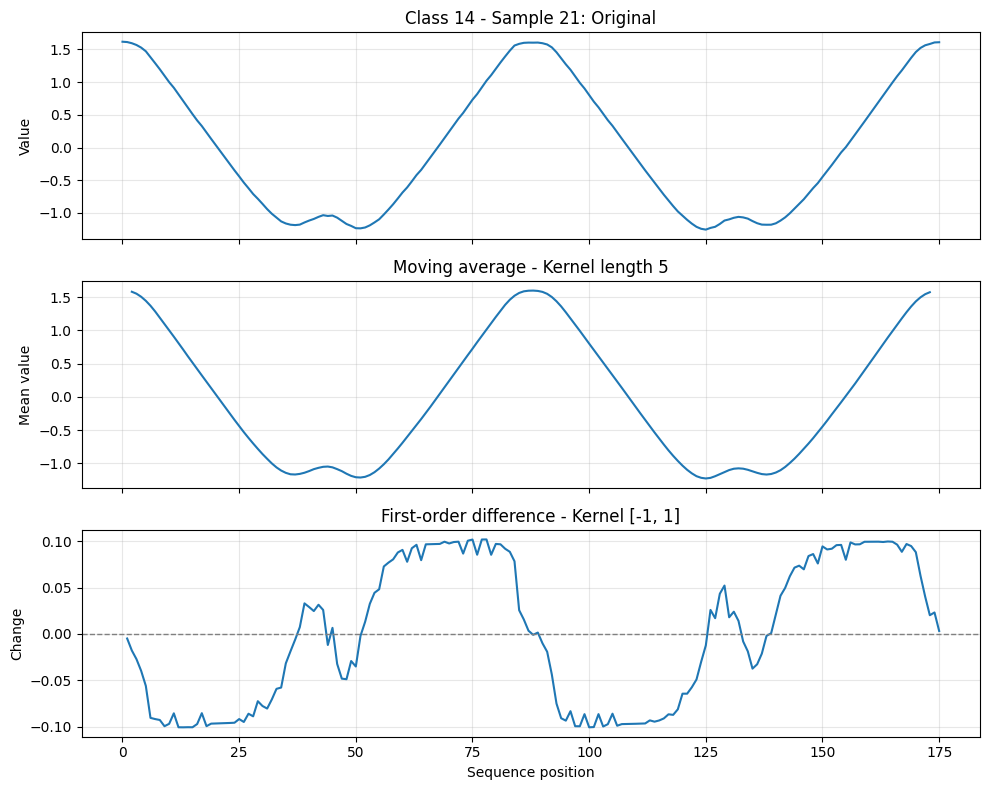

Difference matches np.diff: True


In [8]:
# Apply fixed sliding filters to one training sample
sample_index = np.where(y_train == 14)[0][0]
series = X_train[sample_index]

smoothing_kernel = np.ones(5) / 5
difference_kernel = np.array([-1, 1])

smoothed = np.correlate(series, smoothing_kernel, mode="valid")
difference = np.correlate(series, difference_kernel, mode="valid")

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axes[0].plot(series)
axes[0].set_title(f"Class 14 - Sample {sample_index}: Original")
axes[0].set_ylabel("Value")

# Place each moving average at the centre of its five-point window
axes[1].plot(np.arange(2, len(series) - 2), smoothed)
axes[1].set_title("Moving average - Kernel length 5")
axes[1].set_ylabel("Mean value")

# Place each difference at the later position in the pair
axes[2].plot(np.arange(1, len(series)), difference)
axes[2].set_title("First-order difference - Kernel [-1, 1]")
axes[2].set_ylabel("Change")
axes[2].axhline(0, color="grey", linestyle="--", linewidth=1)

for ax in axes:
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Sequence position")
plt.tight_layout()
plt.show()

print("Difference matches np.diff:", np.allclose(difference, np.diff(series)))

### Applying fixed sliding filters

The five-point moving average makes the selected Class 14 sample slightly smoother while keeping its overall shape. The small rises near the two troughs are still visible after smoothing.

The first-order difference highlights local changes. Positive values indicate an increase between neighbouring positions, while negative values indicate a decrease. Its output matches `np.diff()` for this sample.

These examples illustrate how a sliding filter responds to different features in a sequence. We use `np.correlate()` to apply each kernel without reversing it, consistent with the cross-correlation operation commonly used in CNN layers. In an FCN, the filter weights are learned during training rather than fixed beforehand.

Using `mode="valid"` keeps only complete windows, so the filtered sequences are shorter than the original. This example uses one training sample to illustrate the operations; it does not show whether either transformation improves classification accuracy.

## Step 9. Calculate within-class and between-class distances

Calculate the Euclidean distance for every unique pair of training samples. Separate the distances into within-class and between-class pairs, then compare their means.

Each pair is counted once, and samples are not compared with themselves. We use the sequence values as loaded, without additional scaling.

In [9]:
# Compare distances within and between classes
within_distances = []
between_distances = []

for i in range(len(X_train)):
    for j in range(i + 1, len(X_train)):
        distance = np.linalg.norm(X_train[i] - X_train[j])

        if y_train[i] == y_train[j]:
            within_distances.append(distance)
        else:
            between_distances.append(distance)

print("Within-class pairs:", len(within_distances))
print("Between-class pairs:", len(between_distances))
print("Mean within-class distance:", np.mean(within_distances))
print("Mean between-class distance:", np.mean(between_distances))

Within-class pairs: 1974
Between-class pairs: 73881
Mean within-class distance: 1.1561232624863826
Mean between-class distance: 2.4211180677076936


## Step 10. Plot the distance distributions

Plot the within-class and between-class distances using the same histogram bins. Compare their spread and overlap alongside the mean distances.

Use density normalisation because the two groups contain different numbers of pairs. Each histogram has a total area of one.

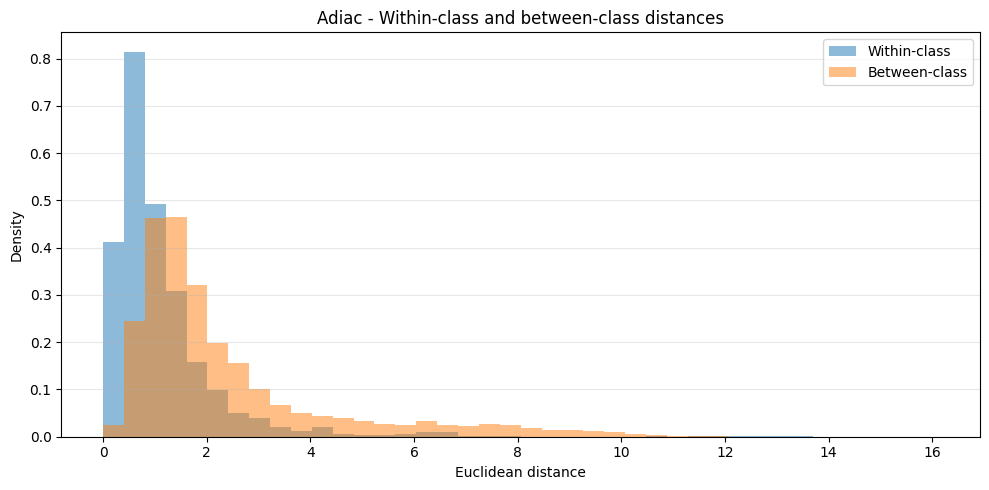

In [10]:
# Use the same bins to compare both distance distributions
bins = np.linspace(
    0,
    max(max(within_distances), max(between_distances)),
    41
)

plt.figure(figsize=(10, 5))

plt.hist(
    within_distances, bins=bins, density=True,
    alpha=0.5, label="Within-class"
)
plt.hist(
    between_distances, bins=bins, density=True,
    alpha=0.5, label="Between-class"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Density")
plt.title("Adiac - Within-class and between-class distances")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Within-class and between-class distances

The mean within-class Euclidean distance is 1.156, compared with 2.421 for between-class pairs. On average, samples from the same class are closer than samples from different classes.

The histogram shows that within-class distances are concentrated at smaller values. Between-class distances are generally larger and have a longer right tail. However, the distributions overlap considerably, so some samples from different classes are also close in Euclidean distance.

This agrees with the earlier plots, where many classes share similar overall shapes. Euclidean distance compares values at matching sequence positions, while an FCN can learn features from local patterns. The distance analysis alone does not tell us how well the FCN will classify these samples.

Both histograms use the same bins and are normalised to density because the numbers of pairs differ. These results use all training pairs, so classes with more samples contribute more pairs. They describe the training data rather than test performance.